In [1]:

# Step 6.1A — Load and validate NLP topic assignments

from pathlib import Path
import pandas as pd
import numpy as np

# Find project root
project_folder = Path.cwd().resolve()

if project_folder.name == "notebooks":
    project_folder = project_folder.parent

results_folder = project_folder / "results"

# Load paper-level NLP results
paper_topics_df = pd.read_csv(
    results_folder / "arxiv_paper_topics.csv"
)

# Load topic descriptions
topic_summary_df = pd.read_csv(
    results_folder / "arxiv_topic_summary.csv"
)

print("PAPER TOPIC DATA")
print("Shape:", paper_topics_df.shape)
print("Columns:", paper_topics_df.columns.tolist())

print("\nTOPIC SUMMARY")
display(topic_summary_df)

print("\nVALIDATION CHECKS")
print("Total papers:", len(paper_topics_df))
print("Unique node IDs:", paper_topics_df["node idx"].nunique())
print("Missing topic assignments:",
      paper_topics_df["dominant_topic"].isna().sum())
print("Number of topics:",
      paper_topics_df["dominant_topic"].nunique())

assert len(paper_topics_df) == 5000
assert paper_topics_df["node idx"].is_unique
assert paper_topics_df["dominant_topic"].notna().all()
assert paper_topics_df["dominant_topic"].nunique() == 12

print("\nTopic data loaded successfully!")


PAPER TOPIC DATA
Shape: (5000, 18)
Columns: ['node idx', 'paper id', 'title', 'dominant_topic', 'topic_strength', 'topic_label', 'topic_0_weight', 'topic_1_weight', 'topic_2_weight', 'topic_3_weight', 'topic_4_weight', 'topic_5_weight', 'topic_6_weight', 'topic_7_weight', 'topic_8_weight', 'topic_9_weight', 'topic_10_weight', 'topic_11_weight']

TOPIC SUMMARY


,topic,topic_label,top_terms,paper_count
0,0,Graph Theory and Spectral Methods,"graph, graphs, spectral, laplacian, edges, ver...",207
1,1,Differential Privacy,"privacy, differential privacy, differential, p...",704
2,2,Theoretical Bounds and Complexity,"log, lower, bounds, bound, epsilon, complexity...",607
3,3,Multi-Armed Bandits and Regret,"regret, bandit, armed, bandits, multi armed, m...",490
4,4,Compressed Sensing and Sparse Recovery,"sensing, sparse, recovery, signal, measurement...",359
5,5,Community Detection,"community, detection, communities, community d...",284
6,6,Deep Learning and Neural Networks,"neural, deep, networks, neural networks, netwo...",337
7,7,Convex and Stochastic Optimization,"convex, optimization, gradient, online, stocha...",408
8,8,Federated Learning,"learning, data, federated, federated learning,...",588
9,9,Subspace Clustering,"clustering, data, subspace, subspace clusterin...",457



VALIDATION CHECKS
Total papers: 5000
Unique node IDs: 5000
Missing topic assignments: 0
Number of topics: 12

Topic data loaded successfully!


In [2]:

# Step 6.1B — Inspect available network-analysis files

from pathlib import Path
import pandas as pd

print("FILES IN RESULTS FOLDER")
print("-" * 55)

for file_path in sorted(results_folder.glob("*")):
    if file_path.is_file():
        print(file_path.name)

print("\nPOTENTIAL COMMUNITY ASSIGNMENT FILES")
print("-" * 55)

keywords = [
    "community",
    "louvain",
    "partition",
    "membership",
    "node"
]

candidate_files = [
    path for path in results_folder.glob("*.csv")
    if any(word in path.name.lower() for word in keywords)
]

for path in candidate_files:
    df = pd.read_csv(path, nrows=5)

    print(f"\nFile: {path.name}")
    print("Columns:", df.columns.tolist())
    display(df.head(3))

if not candidate_files:
    print("No candidate CSV files found.")


FILES IN RESULTS FOLDER
-------------------------------------------------------
.gitkeep
arxiv_betweenness_sensitivity.csv
arxiv_community_agreement.csv
arxiv_community_stability_runs.csv
arxiv_community_stability_summary.csv
arxiv_influence_correlations.csv
arxiv_influence_results.csv
arxiv_influence_top10_overlap.csv
arxiv_paper_topics.csv
arxiv_subset_metadata.csv
arxiv_subset_node_ids.csv
arxiv_topic_summary.csv
karate_algorithm_comparison.csv
karate_centrality_correlations.csv
karate_centrality_rankings.csv
karate_centrality_results.csv
karate_diffusion_baseline.csv
karate_diffusion_probability.csv
karate_diffusion_seed_budget.csv
karate_diffusion_seed_selection.csv
karate_diffusion_summary.csv
karate_louvain_stability.csv
karate_lpa_stability.csv
karate_spectral_k_sensitivity.csv
karate_spectral_pairwise_ari.csv
karate_spectral_stability.csv

POTENTIAL COMMUNITY ASSIGNMENT FILES
-------------------------------------------------------

File: arxiv_community_agreement.csv
Columns: 

,Algorithm A,Algorithm B,NMI,ARI
0,Louvain,Label Propagation,0.717951,0.609155
1,Louvain,Spectral Clustering,0.714618,0.580501
2,Label Propagation,Spectral Clustering,0.684967,0.539473



File: arxiv_community_stability_runs.csv
Columns: ['algorithm', 'seed', 'modularity', 'runtime_seconds', 'n_communities']


,algorithm,seed,modularity,runtime_seconds,n_communities
0,Louvain,0,0.706557,2.796238,14
1,Louvain,1,0.702454,2.015255,14
2,Louvain,2,0.706847,1.911447,15



File: arxiv_community_stability_summary.csv
Columns: ['algorithm', 'mean_modularity', 'std_modularity', 'mean_runtime', 'mean_communities', 'mean_pairwise_ari']


,algorithm,mean_modularity,std_modularity,mean_runtime,mean_communities,mean_pairwise_ari
0,Louvain,0.703525,0.003345,2.332615,14.933333,0.775486
1,Label Propagation,0.659956,0.015079,0.990417,124.866667,0.642693
2,Spectral Clustering,0.657179,0.031138,2.395624,15.000000,0.863161



File: arxiv_subset_node_ids.csv
Columns: ['node idx']


,node idx
0,0
1,31
2,65



File: karate_louvain_stability.csv
Columns: ['seed', 'n_communities', 'modularity', 'nmi', 'ari', 'runtime_seconds']


,seed,n_communities,modularity,nmi,ari,runtime_seconds
0,0,4,0.419790,0.587850,0.464591,0.003215
1,1,4,0.418803,0.489967,0.392239,0.002326
2,2,4,0.418803,0.489967,0.392239,0.001621


In [3]:

# Step 6.1C — Locate Louvain code in the previous notebook

import json

notebook_path = (
    project_folder
    / "notebooks"
    / "05_large_network_analysis.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    previous_notebook = json.load(f)

keywords = [
    "louvain_communities",
    "louvain_partition",
    "best_partition",
    "seed=42",
    "seed = 42"
]

for cell_number, cell in enumerate(
    previous_notebook["cells"], start=1
):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if any(keyword in source for keyword in keywords):
        print(f"\n{'=' * 60}")
        print(f"CELL {cell_number}")
        print(f"{'=' * 60}")
        print(source[:3500])



CELL 12

# Step 4.4A — Louvain community detection

import networkx as nx
import pandas as pd
import numpy as np
import time

RANDOM_SEED = 42

# Run Louvain on the undirected 5,000-node subgraph
start_time = time.perf_counter()

louvain_communities = nx.community.louvain_communities(
    G_subset,
    seed=RANDOM_SEED,
    weight=None,
    resolution=1
)

louvain_runtime = time.perf_counter() - start_time

# Calculate modularity
louvain_modularity = nx.community.modularity(
    G_subset,
    louvain_communities,
    weight=None
)

# Community sizes
community_sizes = sorted(
    [len(c) for c in louvain_communities],
    reverse=True
)

print("LOUVAIN RESULTS")
print("Number of communities:", len(louvain_communities))
print("Modularity:", round(louvain_modularity, 4))
print("Runtime (seconds):", round(louvain_runtime, 4))

print("\nCOMMUNITY SIZES")
print("Largest community:", max(community_sizes))
print("Smallest community:", min(community_sizes))
print("Average community size:",
   

In [4]:

# Step 6.2A — Merge Louvain communities with NLP topics

import pandas as pd

# Load saved Louvain memberships
louvain_membership_df = pd.read_csv(
    results_folder / "arxiv_louvain_membership.csv"
)

print("LOUVAIN MEMBERSHIP DATA")
print("Shape:", louvain_membership_df.shape)
print("Columns:", louvain_membership_df.columns.tolist())

# Merge using original OGBN-Arxiv node identifiers
topic_community_df = paper_topics_df.merge(
    louvain_membership_df,
    on="node idx",
    how="inner",
    validate="one_to_one"
)

print("\nMERGED DATA")
print("Shape:", topic_community_df.shape)

print("\nSAMPLE MATCHED PAPERS")
display(
    topic_community_df[
        [
            "node idx",
            "title",
            "louvain_community",
            "dominant_topic",
            "topic_label"
        ]
    ].head(10)
)

# Validate the join
assert len(topic_community_df) == 5000
assert topic_community_df["node idx"].is_unique
assert topic_community_df["louvain_community"].notna().all()
assert topic_community_df["dominant_topic"].notna().all()

print("\nVALIDATION")
print(
    "Unique Louvain communities:",
    topic_community_df["louvain_community"].nunique()
)
print(
    "Unique NLP topics:",
    topic_community_df["dominant_topic"].nunique()
)

assert topic_community_df["louvain_community"].nunique() == 15
assert topic_community_df["dominant_topic"].nunique() == 12

print("\nLouvain and NLP assignments merged successfully!")


LOUVAIN MEMBERSHIP DATA
Shape: (5000, 2)
Columns: ['node idx', 'louvain_community']

MERGED DATA
Shape: (5000, 19)

SAMPLE MATCHED PAPERS


,node idx,title,louvain_community,dominant_topic,topic_label
0,0,evasion attacks against machine learning at te...,13,11,Adversarial Machine Learning
1,31,learning transformations for clustering and cl...,8,9,Subspace Clustering
2,65,improved analysis for subspace pursuit algorit...,12,4,Compressed Sensing and Sparse Recovery
3,112,rappor randomized aggregatable privacy preserv...,3,1,Differential Privacy
4,148,efficient synthesis of network updates,3,5,Community Detection
5,156,the henchman problem measuring secrecy by the ...,9,2,Theoretical Bounds and Complexity
6,218,diffusing private data over networks,3,1,Differential Privacy
7,226,adm cle approach for detecting slow variables ...,8,2,Theoretical Bounds and Complexity
8,240,map support detection for greedy sparse signal...,12,4,Compressed Sensing and Sparse Recovery
9,244,supervised dimensionality reduction via distan...,11,9,Subspace Clustering



VALIDATION
Unique Louvain communities: 15
Unique NLP topics: 12

Louvain and NLP assignments merged successfully!


In [5]:

# Step 6.2B — Topic distribution within Louvain communities

# Count papers for each community-topic combination
community_topic_counts = pd.crosstab(
    topic_community_df["louvain_community"],
    topic_community_df["dominant_topic"]
)

# Convert counts into percentages within each community
community_topic_pct = (
    community_topic_counts.div(
        community_topic_counts.sum(axis=1),
        axis=0
    ) * 100
)

# Identify the dominant topic in each community
community_topic_summary = pd.DataFrame({
    "community_size": community_topic_counts.sum(axis=1),
    "dominant_topic": community_topic_counts.idxmax(axis=1),
    "dominant_topic_count": community_topic_counts.max(axis=1),
    "dominant_topic_pct": community_topic_pct.max(axis=1)
})

# Attach descriptive topic names
topic_name_map = dict(
    zip(
        topic_summary_df["topic"],
        topic_summary_df["topic_label"]
    )
)

community_topic_summary["dominant_topic_label"] = (
    community_topic_summary["dominant_topic"]
    .map(topic_name_map)
)

print("COMMUNITY-TOPIC COUNTS")
display(community_topic_counts)

print("\nCOMMUNITY-TOPIC PERCENTAGES")
display(community_topic_pct.round(1))

print("\nDOMINANT TOPIC PER COMMUNITY")
display(
    community_topic_summary[
        [
            "community_size",
            "dominant_topic",
            "dominant_topic_label",
            "dominant_topic_count",
            "dominant_topic_pct"
        ]
    ].round(2)
)

# Validate that all papers are included
assert community_topic_counts.to_numpy().sum() == 5000

print("\nAll 5,000 papers accounted for!")


COMMUNITY-TOPIC COUNTS


dominant_topic,0,1,2,3,4,5,6,7,8,9,10,11
louvain_community,,,,,,,,,,,,
0,0,4,39,456,1,10,10,145,36,6,3,4
1,0,0,0,0,0,0,2,0,0,8,0,0
2,0,12,3,10,1,7,1,4,26,8,0,8
3,2,509,99,4,1,9,5,36,102,10,6,21
4,15,5,2,3,1,32,34,7,59,33,4,3
5,1,18,124,1,2,1,3,9,3,2,2,2
6,0,53,8,5,0,2,0,1,12,0,0,1
7,0,0,44,0,1,1,3,1,20,25,1,0
8,66,0,3,1,14,96,22,14,26,217,11,5



COMMUNITY-TOPIC PERCENTAGES


dominant_topic,0,1,2,3,4,5,6,7,8,9,10,11
louvain_community,,,,,,,,,,,,
0,0.0,0.6,5.5,63.9,0.1,1.4,1.4,20.3,5.0,0.8,0.4,0.6
1,0.0,0.0,0.0,0.0,0.0,0.0,20.0,0.0,0.0,80.0,0.0,0.0
2,0.0,15.0,3.8,12.5,1.2,8.8,1.2,5.0,32.5,10.0,0.0,10.0
3,0.2,63.3,12.3,0.5,0.1,1.1,0.6,4.5,12.7,1.2,0.7,2.6
4,7.6,2.5,1.0,1.5,0.5,16.2,17.2,3.5,29.8,16.7,2.0,1.5
5,0.6,10.7,73.8,0.6,1.2,0.6,1.8,5.4,1.8,1.2,1.2,1.2
6,0.0,64.6,9.8,6.1,0.0,2.4,0.0,1.2,14.6,0.0,0.0,1.2
7,0.0,0.0,45.8,0.0,1.0,1.0,3.1,1.0,20.8,26.0,1.0,0.0
8,13.9,0.0,0.6,0.2,2.9,20.2,4.6,2.9,5.5,45.7,2.3,1.1



DOMINANT TOPIC PER COMMUNITY


,community_size,dominant_topic,dominant_topic_label,dominant_topic_count,dominant_topic_pct
louvain_community,,,,,
0,714,3,Multi-Armed Bandits and Regret,456,63.87
1,10,9,Subspace Clustering,8,80.00
2,80,8,Federated Learning,26,32.50
3,804,1,Differential Privacy,509,63.31
4,198,8,Federated Learning,59,29.80
5,168,2,Theoretical Bounds and Complexity,124,73.81
6,82,1,Differential Privacy,53,64.63
7,96,2,Theoretical Bounds and Complexity,44,45.83
8,475,9,Subspace Clustering,217,45.68



All 5,000 papers accounted for!


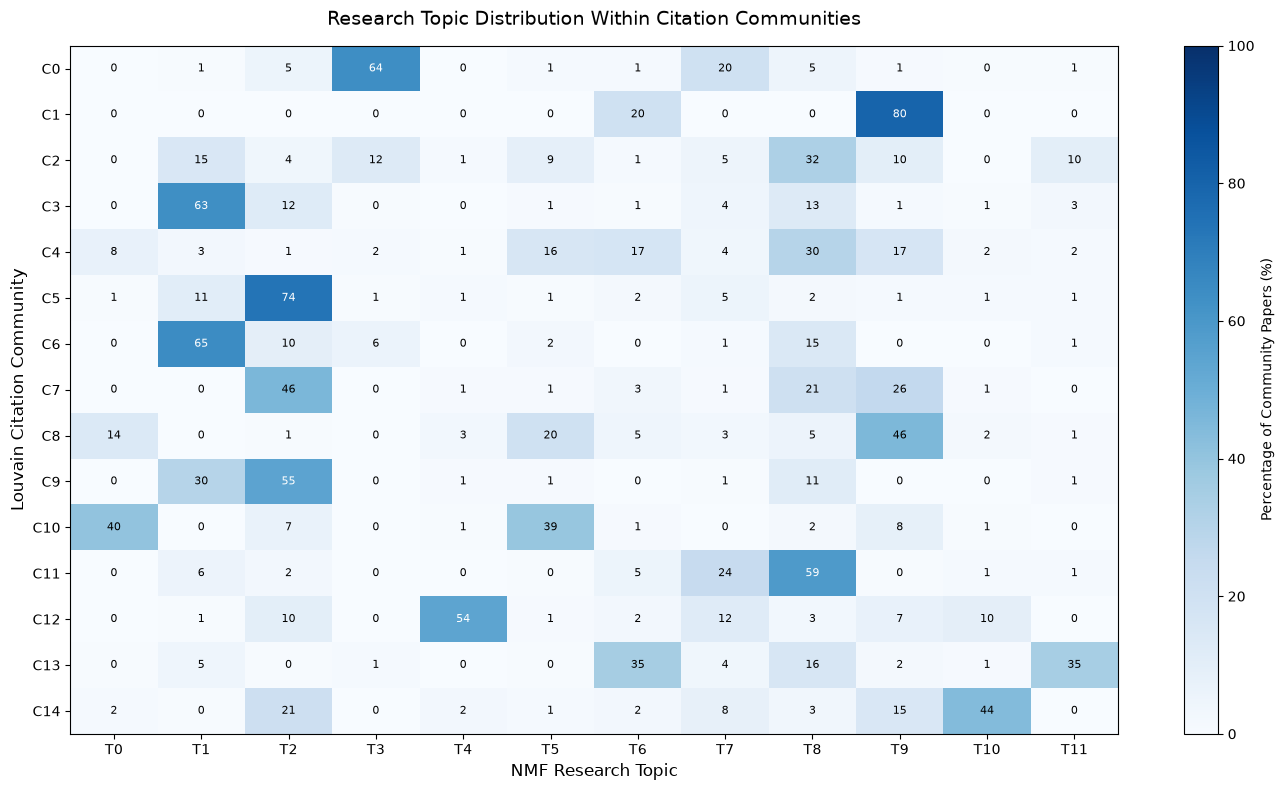

Figure saved to: C:\Users\Lucky\Documents\University_Projects\cos802-network-analysis\figures\arxiv_community_topic_heatmap.png


In [6]:

# Step 6.2C — Visualise topic distribution across communities

import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(14, 8))

heatmap = ax.imshow(
    community_topic_pct.values,
    aspect="auto",
    cmap="Blues",
    vmin=0,
    vmax=100
)

# Label the axes
ax.set_xticks(np.arange(len(community_topic_pct.columns)))
ax.set_xticklabels(
    [
        f"T{topic}"
        for topic in community_topic_pct.columns
    ]
)

ax.set_yticks(np.arange(len(community_topic_pct.index)))
ax.set_yticklabels(
    [
        f"C{community}"
        for community in community_topic_pct.index
    ]
)

ax.set_xlabel("NMF Research Topic", fontsize=12)
ax.set_ylabel("Louvain Citation Community", fontsize=12)

ax.set_title(
    "Research Topic Distribution Within Citation Communities",
    fontsize=14,
    pad=15
)

# Add percentages inside each cell
for i in range(community_topic_pct.shape[0]):
    for j in range(community_topic_pct.shape[1]):
        value = community_topic_pct.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.0f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if value > 50 else "black"
        )

colorbar = fig.colorbar(heatmap, ax=ax)
colorbar.set_label("Percentage of Community Papers (%)")

fig.tight_layout()

# Save figure for the report
output_path = (
    project_folder
    / "figures"
    / "arxiv_community_topic_heatmap.png"
)

fig.savefig(output_path, dpi=300, bbox_inches="tight")

plt.show()

print("Figure saved to:", output_path)


In [7]:

# Step 6.3A — Compare citation communities and NLP topics

from sklearn.metrics import (
    normalized_mutual_info_score,
    adjusted_rand_score
)

# Extract aligned labels from the merged dataset
community_labels = topic_community_df[
    "louvain_community"
].to_numpy()

topic_labels = topic_community_df[
    "dominant_topic"
].to_numpy()

# Calculate agreement metrics
topic_nmi = normalized_mutual_info_score(
    community_labels,
    topic_labels
)

topic_ari = adjusted_rand_score(
    community_labels,
    topic_labels
)

print("CITATION COMMUNITY VS NLP TOPIC AGREEMENT")
print("-" * 50)
print("Number of papers:", len(topic_community_df))
print("Louvain communities:", len(set(community_labels)))
print("NMF topics:", len(set(topic_labels)))

print("\nAGREEMENT METRICS")
print(f"Normalised Mutual Information (NMI): {topic_nmi:.4f}")
print(f"Adjusted Rand Index (ARI):         {topic_ari:.4f}")

# Store results for later reporting
topic_agreement_df = pd.DataFrame([{
    "comparison": "Louvain communities vs NMF topics",
    "n_papers": len(topic_community_df),
    "n_communities": len(set(community_labels)),
    "n_topics": len(set(topic_labels)),
    "NMI": topic_nmi,
    "ARI": topic_ari
}])

display(topic_agreement_df.round(4))


CITATION COMMUNITY VS NLP TOPIC AGREEMENT
--------------------------------------------------
Number of papers: 5000
Louvain communities: 15
NMF topics: 12

AGREEMENT METRICS
Normalised Mutual Information (NMI): 0.4165
Adjusted Rand Index (ARI):         0.3157


,comparison,n_papers,n_communities,n_topics,NMI,ARI
0,Louvain communities vs NMF topics,5000,15,12,0.4165,0.3157
